<a href="https://colab.research.google.com/github/solomon-211/Liner_regression_model_project/blob/main/multivariate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Second-Semester Academic Performance for Early Student Support

**Mission.** To develop and implement innovative educational technologies that bridge the gap in access to quality education for young people in South Sudan and beyond.

**Problem and use case.** Admission to higher education is only the first step towards access; a considerable proportion of students withdraw or fail after their first year, frequently for financial reasons. In this project I predict a student's second-semester average grade (on a 0-20 scale) using only information that is available at the end of the first semester. The intended users are student-support teams, academic advisors and scholarship officers, who can use the prediction to identify at-risk students and offer tutoring, mentoring or financial assistance before failure occurs.

**Dataset.** *Predict Students' Dropout and Academic Success* (Realinho et al., 2022), UCI Machine Learning Repository, CC BY 4.0: https://archive.ics.uci.edu/dataset/697. The dataset contains 4,424 student records and 34 attributes covering demographic, socio-economic, macro-economic and academic information. It was originally released for a classification task (dropout, enrolled or graduate); I reformulate it here as a regression problem on the continuous second-semester grade.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
SEED = 42

## 1. Data Loading and Cleaning

In [2]:
raw = pd.read_csv("dataset.csv")
print(raw.shape)
raw.head()

(4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
raw.info()
print("missing:", raw.isna().sum().sum(), "| duplicates:", raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

The dataset contains no missing values and no duplicate records. Although every column is stored numerically, many represent categorical information encoded as integers, such as the course code (1-17) and binary indicators such as debtor status.

In [4]:
# short names for the columns I keep, so the notebook, API and app all use the same keys
RENAME = {
    "Course": "course",
    "Daytime/evening attendance": "daytime_attendance",
    "Gender": "gender",
    "Scholarship holder": "scholarship_holder",
    "Debtor": "debtor",
    "Tuition fees up to date": "tuition_fees_up_to_date",
    "Displaced": "displaced",
    "Age at enrollment": "age_at_enrollment",
    "Curricular units 1st sem (enrolled)": "sem1_units_enrolled",
    "Curricular units 1st sem (evaluations)": "sem1_units_evaluations",
    "Curricular units 1st sem (approved)": "sem1_units_approved",
    "Curricular units 1st sem (grade)": "sem1_grade",
    "Curricular units 2nd sem (enrolled)": "sem2_units_enrolled",
    "Curricular units 2nd sem (grade)": "sem2_grade",
}
df = raw.rename(columns=RENAME)
TARGET = "sem2_grade"

# students who took no units in semester 2 have no real semester-2 grade
print("not enrolled in sem 2:", (df["sem2_units_enrolled"] == 0).sum())
df = df[df["sem2_units_enrolled"] > 0].reset_index(drop=True)
print("rows left:", len(df))
df[TARGET].describe()

not enrolled in sem 2: 180
rows left: 4244


,sem2_grade
count,4244.000000
mean,10.664098
std,4.865825
min,0.000000
25%,11.000000
50%,12.333333
75%,13.416354
max,18.571429


I excluded the 180 students who were not enrolled in any second-semester units, since a grade of zero in their case reflects non-enrolment rather than academic failure.

## 2. Exploratory Data Analysis

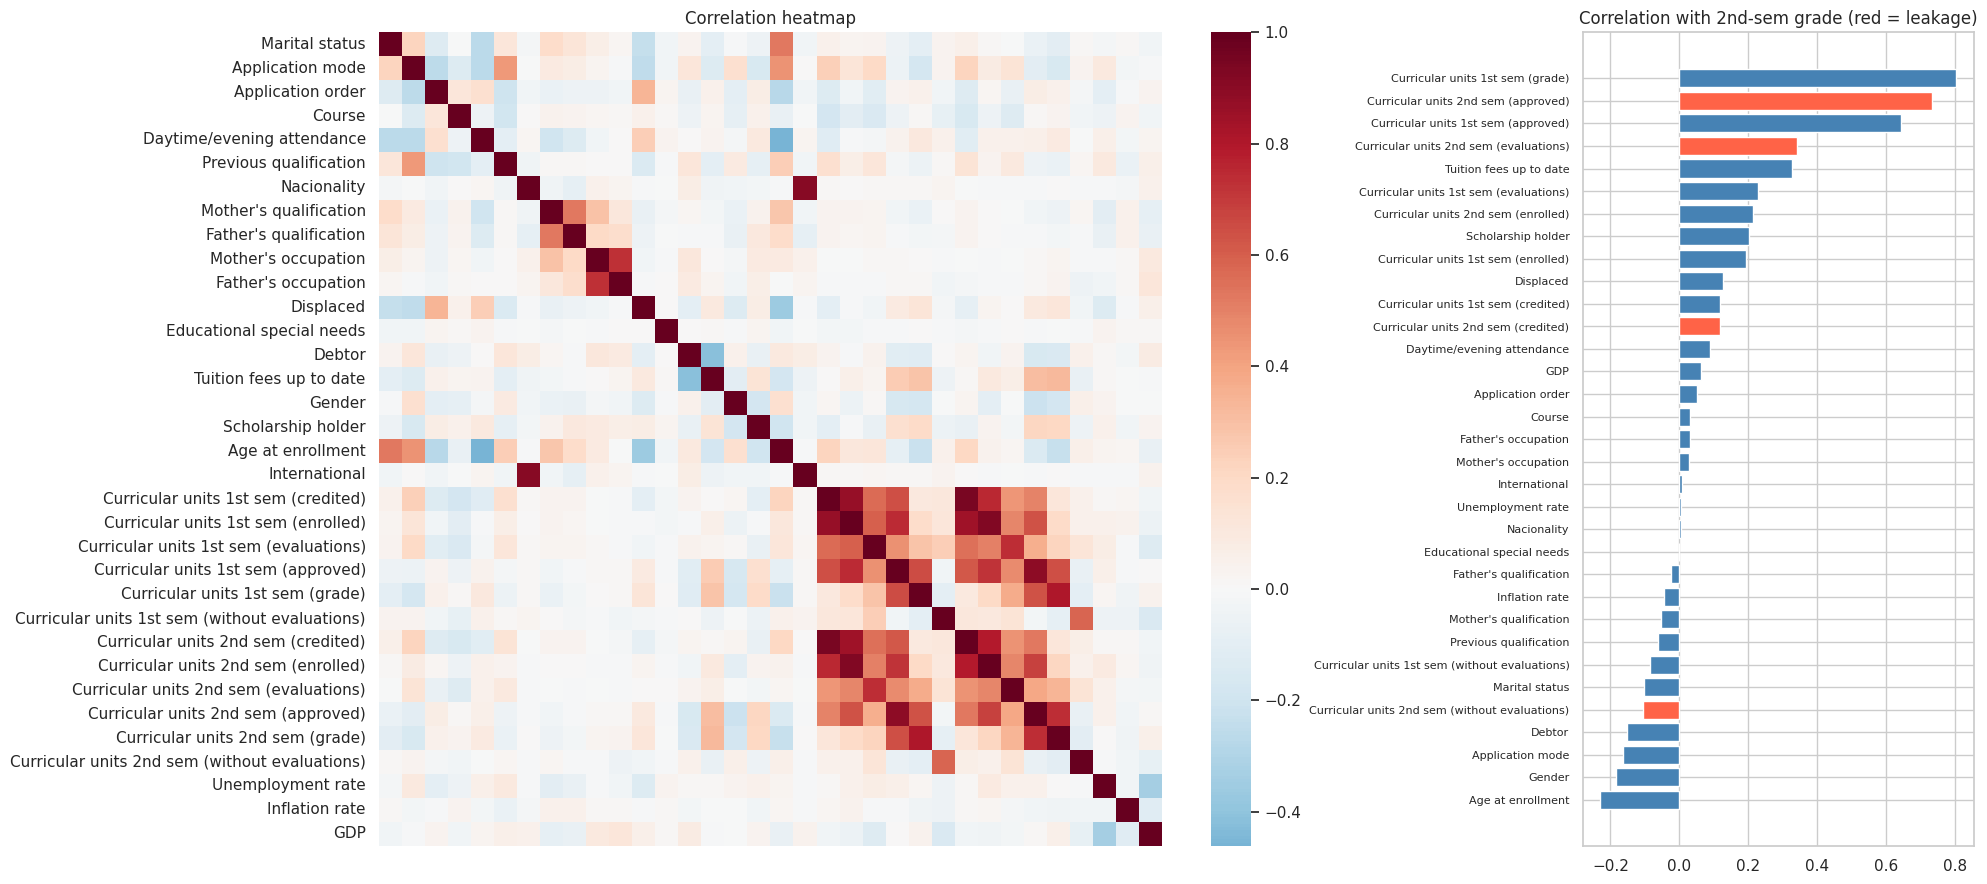

In [5]:
num_cols = raw.drop(columns="Target").columns
corr = df.rename(columns={v: k for k, v in RENAME.items()})[num_cols].corr()
target_corr = corr["Curricular units 2nd sem (grade)"].drop("Curricular units 2nd sem (grade)").sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={"width_ratios": [3, 1.2]})
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax1, xticklabels=False)
ax1.set_title("Correlation heatmap")
leak = ["2nd sem" in c and "enrolled" not in c for c in target_corr.index]
ax2.barh(target_corr.index, target_corr.values, color=np.where(leak, "tomato", "steelblue"))
ax2.set_title("Correlation with 2nd-sem grade (red = leakage)")
ax2.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

The first-semester grade (r = 0.80) and the number of first-semester units passed (r = 0.64) show the strongest association with the target, followed by tuition-fee status (0.33) and age at enrolment (-0.23). The attributes shown in red record second-semester outcomes, which are only known after the period being predicted; I therefore excluded them to prevent data leakage. National indicators (GDP, inflation and unemployment), nationality and parental occupation are almost uncorrelated with the target, so I excluded these as well.

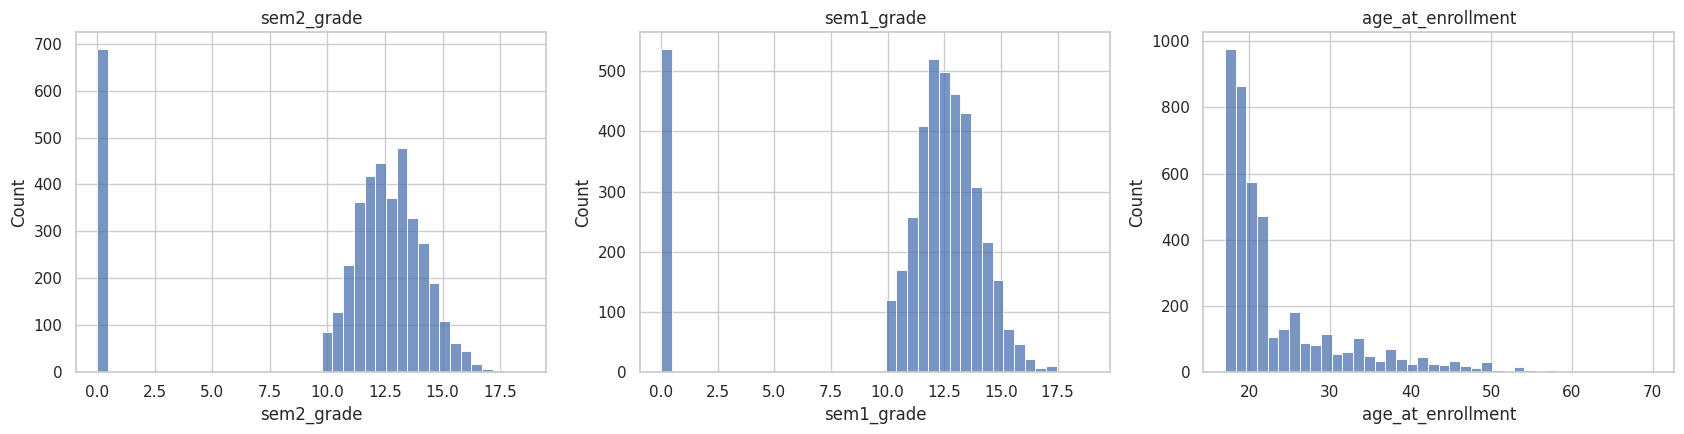

sem2_grade == 0: 16.3% of students


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, [TARGET, "sem1_grade", "age_at_enrollment"]):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()
print(f"sem2_grade == 0: {(df[TARGET] == 0).mean():.1%} of students")

The target distribution is bimodal: approximately 16% of students obtain a second-semester grade of exactly zero (no units passed), while the remainder fall between 10 and 18.6, since a unit is only credited once a grade of at least 10 is achieved. A linear model cannot represent this discontinuity well, which motivated the inclusion of tree-based models in the comparison. Because age at enrolment is right-skewed, I standardised all features before training.

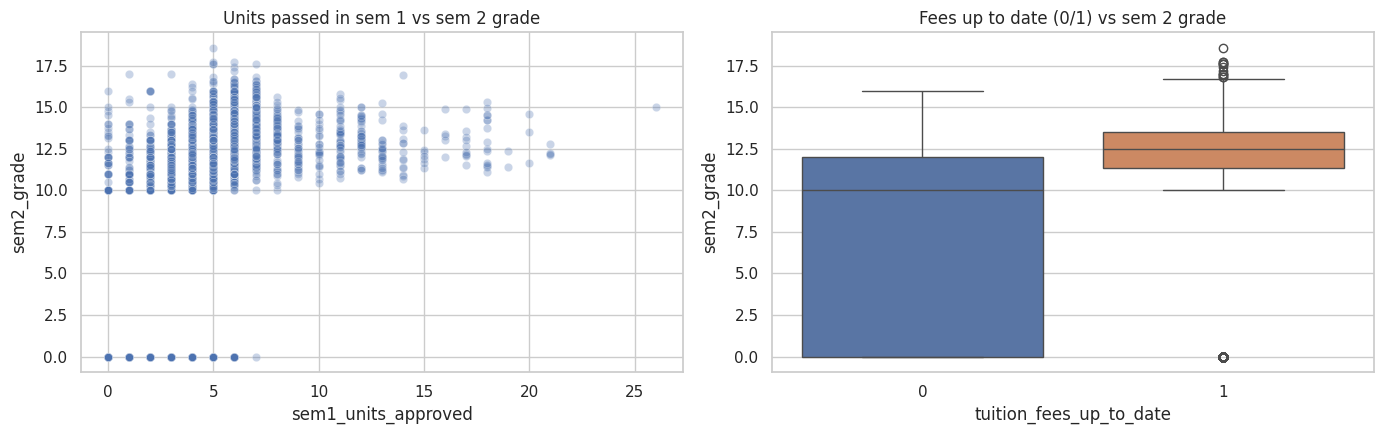

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=df, x="sem1_units_approved", y=TARGET, alpha=0.3, ax=ax1)
sns.boxplot(data=df, x="tuition_fees_up_to_date", y=TARGET, hue="tuition_fees_up_to_date", legend=False, ax=ax2)
ax1.set_title("Units passed in sem 1 vs sem 2 grade")
ax2.set_title("Fees up to date (0/1) vs sem 2 grade")
plt.tight_layout()
plt.show()

A second-semester grade of zero occurs only among students who passed seven or fewer units in the first semester. Students with outstanding tuition fees have a median grade of 10 and a high proportion of zeros, whereas students whose fees are up to date are concentrated around 12.5. I retained both variables; the latter finding is particularly relevant to my mission, as it indicates that financial barriers translate directly into academic outcomes.

## 3. Feature Engineering
I selected 13 features: the course (categorical), six binary indicators (attendance mode, gender, scholarship holder, debtor, tuition fees up to date, displaced), and six numeric variables (age at enrolment; first-semester units enrolled, evaluated and approved; first-semester grade; second-semester units enrolled).

The following attributes were removed:
- `Target` and the second-semester approved, evaluated, credited and without-evaluation counts, because they constitute data leakage.
- GDP, inflation rate and unemployment rate, which are constant for all students within a given year.
- Marital status, application mode and order, previous qualification, nationality, international status, special educational needs, and parental qualification and occupation, all of which are weakly correlated with the target (|r| < 0.17); the parental attributes would also introduce 29-46 categories each.
- First-semester credited units and units without evaluation, which are weakly correlated (|r| ≈ 0.1) and largely redundant with the other first-semester variables.

In [8]:
CATEGORICAL = ["course"]
BINARY = ["daytime_attendance", "gender", "scholarship_holder", "debtor", "tuition_fees_up_to_date", "displaced"]
NUMERIC = ["age_at_enrollment", "sem1_units_enrolled", "sem1_units_evaluations",
           "sem1_units_approved", "sem1_grade", "sem2_units_enrolled"]
FEATURES = CATEGORICAL + BINARY + NUMERIC

df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(2)

,sem2_grade
sem1_grade,0.80
sem1_units_approved,0.64
tuition_fees_up_to_date,0.33
sem1_units_evaluations,0.23
sem2_units_enrolled,0.21
scholarship_holder,0.20
sem1_units_enrolled,0.19
displaced,0.12
daytime_attendance,0.09
course,0.03


The most influential features are `sem1_grade` and `sem1_units_approved`, followed by tuition-fee status, age at enrolment, the number of first-semester evaluations and scholarship status.

## 4. Encoding, Train-Test Split and Standardisation
The course variable is one-hot encoded, as its codes are nominal labels rather than quantities; the remaining binary indicators are already numeric. I divided the data into training (80%) and test (20%) sets and fitted the scaler on the training set only, to avoid information leakage from the test set.

In [9]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# course is a label (1-17), not a quantity, so it gets one-hot encoded
preprocessor = ColumnTransformer([
    ("course", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ("scale", StandardScaler(), BINARY + NUMERIC),
])
X_train_s = preprocessor.fit_transform(X_train)  # fit on train only
X_test_s = preprocessor.transform(X_test)
X_train_s.shape, X_test_s.shape

((3395, 29), (849, 29))

## 5. Linear Regression by Gradient Descent (SGDRegressor)
I tuned three hyperparameters (learning rate, L2 regularisation strength and number of epochs) on a validation set drawn from the training data, so that the test set remained unseen until the final evaluation. The model is trained one epoch at a time using `partial_fit`, which allows the loss to be recorded after each epoch.

In [10]:
# validation set taken from the training data, so tuning never sees the test set
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train, test_size=0.2, random_state=SEED)


def train_sgd(X_a, y_a, X_b, y_b, eta0, alpha, epochs):
    model = SGDRegressor(eta0=eta0, alpha=alpha, random_state=SEED)
    rng = np.random.default_rng(SEED)
    loss_a, loss_b = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(X_a))  # reshuffle every epoch
        model.partial_fit(X_a[idx], y_a.values[idx])
        loss_a.append(mean_squared_error(y_a, model.predict(X_a)))
        loss_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, loss_a, loss_b


lrs = [0.0001, 0.001, 0.01, 0.05]
alphas = [0.0001, 0.01, 0.1, 1.0]
epoch_options = [5, 20, 50, 100, 150]

curves, rows = {}, []
for lr in lrs:
    for alpha in alphas:
        _, _, val_loss = train_sgd(X_tr, y_tr, X_val, y_val, lr, alpha, 150)
        curves[(lr, alpha)] = val_loss
        for ep in epoch_options:
            # average of the last 5 epochs, because single epochs are noisy
            rows.append([lr, alpha, ep, np.mean(val_loss[ep - 5:ep])])

tuning = pd.DataFrame(rows, columns=["eta0", "alpha", "epochs", "val_mse"]).sort_values("val_mse")
tuning.head(10).round(3)

,eta0,alpha,epochs,val_mse
49,0.010,0.01,150,8.319
47,0.010,0.01,50,8.332
29,0.001,0.01,150,8.334
46,0.010,0.01,20,8.335
48,0.010,0.01,100,8.337
24,0.001,0.00,150,8.340
41,0.010,0.00,20,8.347
28,0.001,0.01,100,8.356
44,0.010,0.00,150,8.357
42,0.010,0.00,50,8.358


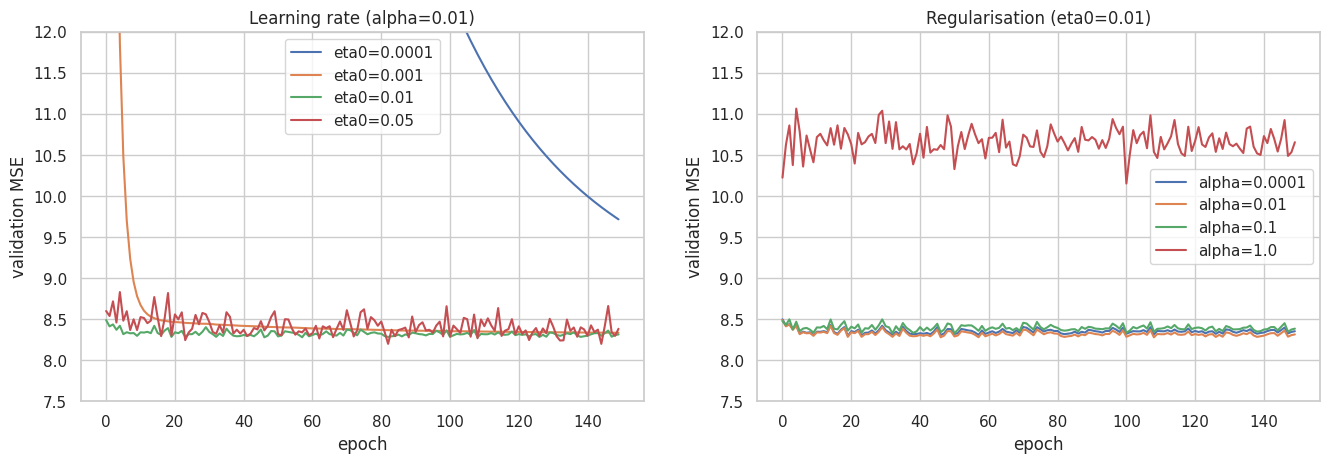

best: 0.01 0.01 150


In [11]:
best_lr, best_alpha, best_epochs = tuning.iloc[0][["eta0", "alpha", "epochs"]]
best_epochs = int(best_epochs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.8))
for lr in lrs:
    ax1.plot(curves[(lr, best_alpha)], label=f"eta0={lr}")
for alpha in alphas:
    ax2.plot(curves[(best_lr, alpha)], label=f"alpha={alpha}")
ax1.set(title=f"Learning rate (alpha={best_alpha})", xlabel="epoch", ylabel="validation MSE", ylim=(7.5, 12))
ax2.set(title=f"Regularisation (eta0={best_lr})", xlabel="epoch", ylabel="validation MSE", ylim=(7.5, 12))
ax1.legend()
ax2.legend()
plt.show()
print("best:", best_lr, best_alpha, best_epochs)

A learning rate of 0.0001 converges too slowly, with validation MSE still near 9.7 after 150 epochs, whereas 0.01 converges almost immediately and remains stable; 0.05 converges but fluctuates because of its larger step size. Regularisation strengths up to 0.1 produce similar validation MSE (approximately 8.3), while alpha = 1.0 leads to underfitting (approximately 10.7). Once the learning rate is appropriate, additional epochs change the loss by less than 0.05.

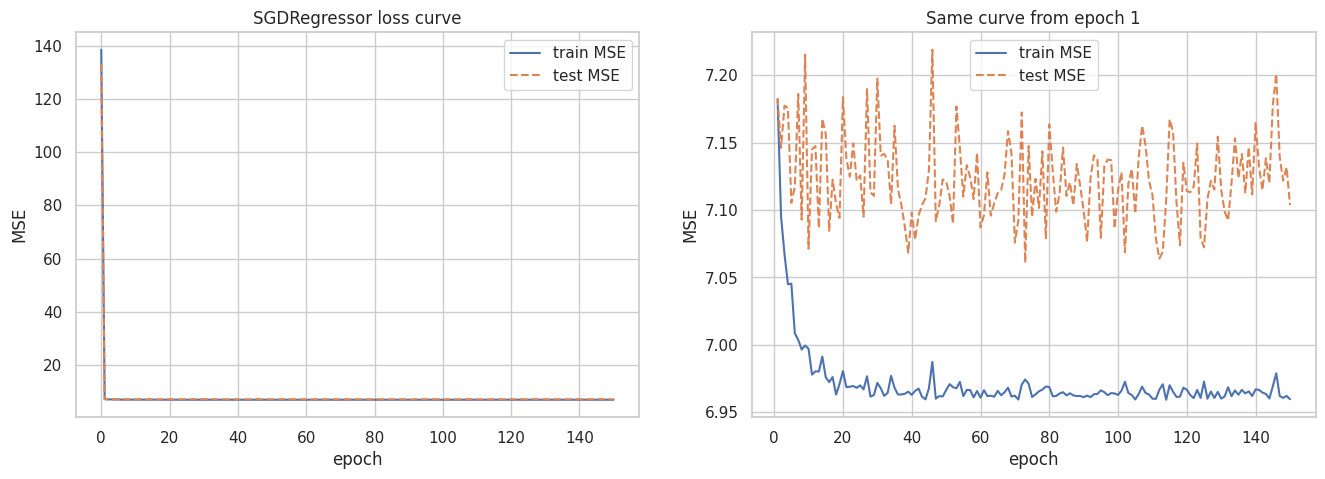

epoch 0: 138.5 / 133.1
epoch 1: 7.18 / 7.18
epoch 150: 6.96 / 7.10


In [12]:
sgd, train_loss, test_loss = train_sgd(X_train_s, y_train, X_test_s, y_test, best_lr, best_alpha, best_epochs)

# epoch 0 = untrained model (all weights 0, so it predicts 0)
train_loss = [mean_squared_error(y_train, np.zeros(len(y_train)))] + train_loss
test_loss = [mean_squared_error(y_test, np.zeros(len(y_test)))] + test_loss

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
for ax, start in [(ax1, 0), (ax2, 1)]:
    ax.plot(range(start, best_epochs + 1), train_loss[start:], label="train MSE")
    ax.plot(range(start, best_epochs + 1), test_loss[start:], "--", label="test MSE")
    ax.set(xlabel="epoch", ylabel="MSE")
    ax.legend()
ax1.set_title("SGDRegressor loss curve")
ax2.set_title("Same curve from epoch 1")
plt.show()
print(f"epoch 0: {train_loss[0]:.1f} / {test_loss[0]:.1f}")
print(f"epoch 1: {train_loss[1]:.2f} / {test_loss[1]:.2f}")
print(f"epoch {best_epochs}: {train_loss[-1]:.2f} / {test_loss[-1]:.2f}")

Before training, the model (with all weights set to zero) has an MSE of approximately 138, which falls to 7.2 after the first epoch. Thereafter, the training MSE stabilises around 6.96 and the test MSE around 7.1. The gap between the two curves is small and does not widen, indicating that the model is not overfitting; its remaining error reflects bias, since a linear function cannot capture the discontinuity between zero and passing grades.

## 6. Closed-Form Linear Regression, Decision Tree and Random Forest
The maximum depth of the decision tree and the minimum leaf size of the random forest were selected on the same validation set.

In [13]:
lin = LinearRegression().fit(X_train_s, y_train)


def val_mse(model):
    model.fit(X_tr, y_tr)
    return mean_squared_error(y_val, model.predict(X_val))


depth_scores = {d: val_mse(DecisionTreeRegressor(max_depth=d, random_state=SEED)) for d in [3, 4, 5, 6, 8, 10, None]}
leaf_scores = {l: val_mse(RandomForestRegressor(200, min_samples_leaf=l, random_state=SEED, n_jobs=-1)) for l in [1, 3, 5, 10]}
print("tree max_depth:", {k: round(v, 2) for k, v in depth_scores.items()})
print("forest min_samples_leaf:", {k: round(v, 2) for k, v in leaf_scores.items()})

best_depth = min(depth_scores, key=depth_scores.get)
best_leaf = min(leaf_scores, key=leaf_scores.get)
tree = DecisionTreeRegressor(max_depth=best_depth, random_state=SEED).fit(X_train_s, y_train)
forest = RandomForestRegressor(300, min_samples_leaf=best_leaf, random_state=SEED, n_jobs=-1).fit(X_train_s, y_train)

tree max_depth: {3: 8.15, 4: 7.94, 5: 7.99, 6: 8.64, 8: 9.41, 10: 10.63, None: 12.07}
forest min_samples_leaf: {1: 7.64, 3: 7.49, 5: 7.39, 10: 7.42}


The decision tree overfits rapidly: its validation MSE increases from 7.94 at a depth of 4 to 12.51 when depth is unrestricted.

### Model Comparison

In [14]:
models = {"SGDRegressor": sgd, "LinearRegression": lin, "DecisionTree": tree, "RandomForest": forest}
results = pd.DataFrame(
    [[mean_squared_error(y_train, m.predict(X_train_s)), mean_squared_error(y_test, m.predict(X_test_s))] for m in models.values()],
    index=models.keys(), columns=["train_mse", "test_mse"],
).sort_values("test_mse")
best_name = results.index[0]
print("best model:", best_name)
results.round(3)

best model: RandomForest


,train_mse,test_mse
RandomForest,4.059,6.761
DecisionTree,6.448,6.790
SGDRegressor,6.960,7.104
LinearRegression,6.949,7.117


**Selected model: random forest, test MSE = 6.76** (an average error of approximately 2.6 grade points). The selection criterion is the lowest mean squared error on the common held-out test set.

- SGDRegressor and LinearRegression achieve almost identical results (7.10 and 7.12), as gradient descent converges towards the same least-squares solution that the closed-form method computes directly. Both are limited by the bimodal structure of the target.
- The decision tree (6.79) captures the zero-grade group through threshold rules such as "approved units ≤ 7", but requires a depth constraint to avoid overfitting.
- The random forest averages 300 trees, retaining the tree's ability to model thresholds while reducing variance. Its training MSE (4.06) is lower than its test MSE, indicating mild overfitting, yet it generalises best of the four models. This is important for the use case, since failing to identify an at-risk student is the most costly type of error.

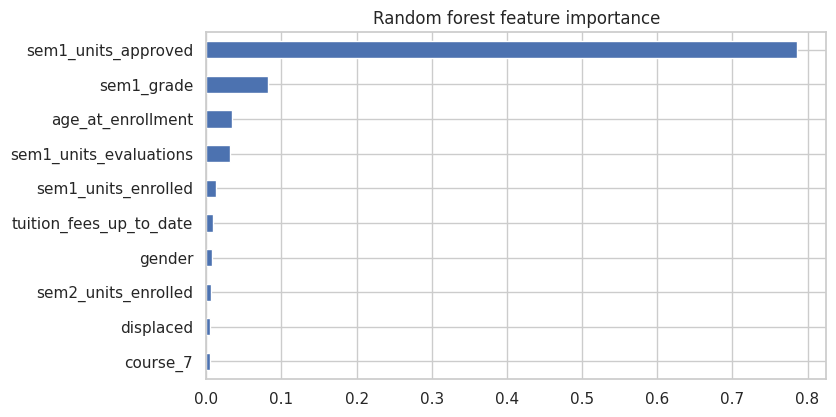

In [15]:
names = [n.split("__")[1] for n in preprocessor.get_feature_names_out()]
pd.Series(forest.feature_importances_, index=names).nlargest(10).sort_values().plot.barh(figsize=(8, 4.5))
plt.title("Random forest feature importance")
plt.show()

The random forest relies primarily on the number of first-semester units passed, followed by the first-semester grade.

## 7. Relationship Between the Strongest Predictor and the Target
The scatter plot below shows the feature most strongly correlated with the target before any model is fitted.

sem1_grade


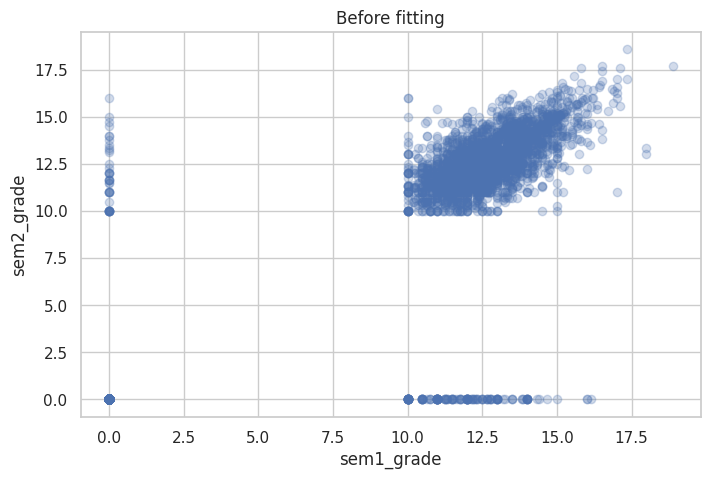

In [16]:
top = df[FEATURES].corrwith(df[TARGET]).abs().idxmax()
print(top)
plt.figure(figsize=(8, 5))
plt.scatter(X_train[top], y_train, alpha=0.25)
plt.xlabel(top)
plt.ylabel(TARGET)
plt.title("Before fitting")
plt.show()

The same data with a fitted line from a single-feature linear regression, trained solely for this visualisation:

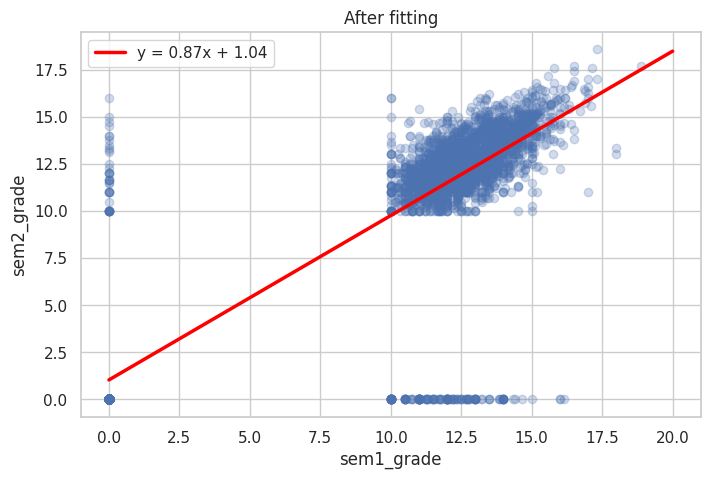

one-feature test MSE: 8.46


In [17]:
line = LinearRegression().fit(X_train[[top]], y_train)
xs = pd.DataFrame({top: np.linspace(0, 20, 50)})

plt.figure(figsize=(8, 5))
plt.scatter(X_train[top], y_train, alpha=0.25)
plt.plot(xs[top], line.predict(xs), color="red", linewidth=2.5,
         label=f"y = {line.coef_[0]:.2f}x + {line.intercept_:.2f}")
plt.xlabel(top)
plt.ylabel(TARGET)
plt.title("After fitting")
plt.legend()
plt.show()
print("one-feature test MSE:", round(mean_squared_error(y_test, line.predict(X_test[[top]])), 2))

The fitted slope of approximately 0.87 indicates that each additional point in the first-semester grade corresponds to almost one additional point in the second semester. However, this single-feature model achieves a test MSE of 8.46, as it cannot account for students who passed in the first semester but obtained zero in the second. This limitation justifies the use of all 13 features in the final model.

## 8. Saving the Selected Model
I saved the one-hot encoder, the scaler and the random forest together as a single scikit-learn Pipeline using joblib, so that the API can accept raw input values. The cleaned training data is also saved, as the API's retraining endpoint combines it with newly uploaded records.

In [18]:
import os

os.makedirs("../API", exist_ok=True)  # the API folder sits next to this notebook's folder
best_model = Pipeline([("preprocess", preprocessor), ("model", models[best_name])])
joblib.dump(best_model, "../API/best_model.pkl")

# /retrain in the API refits on this data plus the uploaded rows
df[FEATURES + [TARGET]].to_csv("../API/training_data.csv", index=False)

## 9. Prediction for a Single Test Record
The function below loads the saved Pipeline and predicts the target for one row of the test set; the API reuses the same logic.

In [19]:
def predict_one(row, path="../API/best_model.pkl"):
    model = joblib.load(path)
    return model.predict(row[FEATURES])[0]


row = X_test.iloc[[0]]
display(row)
print("predicted:", round(predict_one(row), 2))
print("actual:   ", y_test.iloc[0])

,course,daytime_attendance,gender,scholarship_holder,debtor,tuition_fees_up_to_date,displaced,age_at_enrollment,sem1_units_enrolled,sem1_units_evaluations,sem1_units_approved,sem1_grade,sem2_units_enrolled
1992,14,1,0,0,0,1,1,20,6,9,6,13.285714,6


predicted: 12.84
actual:    13.8


The predicted grade of 12.84 lies within approximately one point of the actual value of 13.8, which is better than the model's average error.